# What if the device were better?

Calibration values can be overridden per job. That turns a twin into a what-if tool: how much would a better two-qubit
gate, better readout or longer coherence help a given circuit?

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': '02f7e5c0c4f6:7:0b2c9c',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. A better two-qubit gate

GHZ₈ on Emerald as its CZ fidelity is raised from the published median. The gain stops early: the noise report marks the CZ `budget_limited` once the T1/T2 relaxation during its own duration costs more than the requested infidelity, so a better gate also needs longer coherence (example 3).

In [2]:
target = ["0" * 8, "1" * 8]
rows = [{"CZ fidelity": "published", "GHZ8 success": success(run("iqm_emerald", ghz(8), shots=50000, noise=True), target)}]
for f in (0.995, 0.998, 0.999, 0.9999):
    r = run("iqm_emerald", ghz(8), shots=50000, noise={"model": "device", "two_qubit_fidelity": f})
    rows.append({"CZ fidelity": f, "GHZ8 success": success(r, target),
                 "CZ budget-limited": r["result"]["noise"]["per_gate"]["cz"]["budget_limited"]})
pd.DataFrame(rows).set_index("CZ fidelity").round(4)

,GHZ8 success,CZ budget-limited
CZ fidelity,,
published,0.6980,NaN
0.995,0.6980,False
0.998,0.7057,True
0.999,0.7057,True
0.9999,0.7057,True


## 2. Better readout

Readout dominates the error budget of the median-based superconducting twins. Raising readout fidelity alone moves GHZ success the most.

In [3]:
target = ["0" * 8, "1" * 8]
rows = []
for f in (0.97, 0.98, 0.99, 0.995, 0.999):
    r = run("rigetti_ankaa_3", ghz(8), shots=50000, noise={"model": "device", "readout_fidelity": f})
    rows.append({"readout fidelity": f, "GHZ8 success": success(r, target)})
pd.DataFrame(rows).set_index("readout fidelity").round(4)

,GHZ8 success
readout fidelity,
0.970,0.6628
0.980,0.7200
0.990,0.7809
0.995,0.8129
0.999,0.8378


## 3. Longer coherence

T1 and T2 can be overridden too (T2 at most 2·T1). Idle relaxation shrinks as coherence grows.

In [4]:
target = ["0" * 8, "1" * 8]
rows = []
for t1 in (20, 50, 100, 300, 1000):
    r = run("iqm_emerald", ghz(8), shots=50000, noise={"model": "device", "t1_us": t1, "t2_us": t1})
    rows.append({"T1 = T2 (us)": t1, "GHZ8 success": success(r, target)})
pd.DataFrame(rows).set_index("T1 = T2 (us)").round(4)

,GHZ8 success
T1 = T2 (us),
20,0.6779
50,0.7240
100,0.7395
300,0.7503
1000,0.7542


## 4. Scaling every error rate

`scale` multiplies every error rate. Plotting GHZ₅ success against it shows how much margin each twin has.

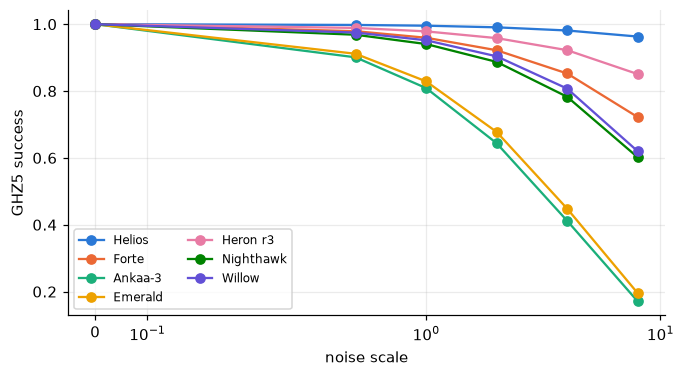

In [5]:
scales = [0, 0.5, 1, 2, 4, 8]
target = ["00000", "11111"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for b in ALL_BACKENDS:
    ys = [success(run(b, ghz(5), shots=20000, routing=True, noise={"model": "device", "scale": s}), target) for s in scales]
    ax.plot(scales, ys, "o-", color=COLORS[b], label=NAMES[b])
ax.set_xscale("symlog", linthresh=0.5); ax.set_xlabel("noise scale"); ax.set_ylabel("GHZ5 success")
ax.legend(ncols=2, fontsize=8); plt.show()

## 5. How good must a device be?

Search for the two-qubit fidelity at which a 10-qubit GHZ on the Ankaa-3 lattice would reach 90 % success, keeping everything else at its published or assumed value.

In [6]:
target = ["0" * 10, "1" * 10]
def ghz10(f):
    return success(run("rigetti_ankaa_3", ghz(10), shots=20000, noise={"model": "device", "two_qubit_fidelity": f}), target)
lo, hi = 0.99, 0.999999
print("published:", round(success(run("rigetti_ankaa_3", ghz(10), shots=20000, noise=True), target), 4))
print("with a perfect 2Q gate:", round(ghz10(0.999999), 4))
if ghz10(hi) < 0.9:
    print("Even a perfect two-qubit gate does not reach 0.9: the other channels (readout, relaxation) dominate.")
else:
    for _ in range(12):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if ghz10(mid) < 0.9 else (lo, mid)
    print(f"two-qubit fidelity needed: about {hi:.5f}")

published: 0.5732
with a perfect 2Q gate: 0.6036
Even a perfect two-qubit gate does not reach 0.9: the other channels (readout, relaxation) dominate.


## Takeaways

- Overrides make each twin a what-if tool for hardware roadmaps.
- The error budget tells which improvement pays off first.